<a href="https://colab.research.google.com/github/OutisAyo/ML/blob/main/MS4S08_CW2_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MS4S08 Applied Statistics for Data Science: CW2 analysis notebook

This notebook answers the three CW2 questions using the methods taught in the module (Weeks 4 to 8). Each question follows the same order as the report: look at the data, check assumptions, run the analysis, then interpret.

Place `Q1_relationships.csv`, `Q2_dimensionality.csv` and `Q3_clustering.csv` in the same folder as this notebook. Every figure used in the report is saved to a `figures` folder.

In [10]:
!pip -q install factor_analyzer && mv -n /Q1_relationships.csv /Q2_dimensionality.csv /Q3_clustering.csv /content/ ; ls /content

figures		      Q2_dimensionality.csv  sample_data
Q1_relationships.csv  Q3_clustering.csv


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer import FactorAnalyzer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.manifold import MDS
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette
from matplotlib.colors import LinearSegmentedColormap
import itertools, os

import warnings
warnings.filterwarnings('ignore')

In [12]:
!pip -q install factor_analyzer

Chart style used for every figure: a colour-blind-safe palette, light gridlines and a diverging red-grey-blue scale for correlation matrices (red = negative, blue = positive).

In [13]:
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
DIVERGING = LinearSegmentedColormap.from_list('diverging', ['#e34948', '#f0efec', '#2a78d6'])

plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 200, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
    'axes.labelcolor': INK2, 'axes.edgecolor': '#c3c2b7',
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'legend.frameon': False})

os.makedirs('figures', exist_ok=True)
def save(name):
    # save the current figure so it can be pasted into the report
    plt.savefig(f'figures/{name}.png', bbox_inches='tight', facecolor='white')

---
## Question 1: What is associated with final exam performance?

**Plan.** (1) Check the data (missing values, ranges, outliers). (2) Look at the shape of each variable and test normality with Shapiro-Wilk, because Pearson's correlation and linear regression work best with roughly normal data. (3) Measure how strongly each indicator moves with `FinalExamScore` (Pearson, with Spearman as a check). (4) Fit a multiple regression to find which indicators still matter once the others are taken into account, removing non-significant predictors one at a time (as in Week 6). (5) Check the regression assumptions on the residuals.

In [14]:
df1 = pd.read_csv('Q1_relationships.csv')
df1.head()

,StudyHoursIndex,AttendanceScore,CourseworkScore,ProjectScore,OnlineEngagement,FinalExamScore
0,67.5,53.1,67.8,52.4,47.0,62.3
1,57.9,56.3,66.0,54.0,57.1,67.8
2,69.7,65.4,79.7,75.3,70.6,65.3
3,82.8,70.0,87.8,78.8,76.4,80.1
4,56.5,57.9,50.4,50.0,58.9,48.5


In [15]:
print(df1.shape)
print('Missing values:', df1.isna().sum().sum(), '| Duplicate rows:', df1.duplicated().sum())
df1.describe().round(2)

(100, 6)
Missing values: 0 | Duplicate rows: 0


,StudyHoursIndex,AttendanceScore,CourseworkScore,ProjectScore,OnlineEngagement,FinalExamScore
count,100.00,100.00,100.00,100.00,100.00,100.00
mean,58.44,61.13,64.14,59.55,65.12,59.94
std,13.63,12.53,14.84,11.73,14.05,10.33
min,20.70,33.00,27.40,35.90,34.10,29.60
25%,51.00,52.88,54.35,51.60,55.78,52.92
50%,58.10,61.15,65.35,58.75,65.25,60.80
75%,66.07,68.00,72.62,66.58,74.48,66.53
max,87.80,97.40,100.00,89.70,100.00,86.20


### 1.1 Distributions, normality and outliers

In [16]:
# Shapiro-Wilk: H0 = the variable is normally distributed. p > 0.05 means no evidence against normality.
q1_normality = pd.DataFrame({
    'Shapiro-Wilk W': [stats.shapiro(df1[c]).statistic for c in df1],
    'p-value': [stats.shapiro(df1[c]).pvalue for c in df1],
    'Skewness': df1.skew().values}, index=df1.columns)

# Outliers using the box-plot rule: more than 1.5 x IQR beyond the quartiles
Q1q, Q3q = df1.quantile(0.25), df1.quantile(0.75)
IQR = Q3q - Q1q
q1_normality['Outliers (1.5 x IQR)'] = ((df1 < Q1q - 1.5*IQR) | (df1 > Q3q + 1.5*IQR)).sum()
q1_normality.round(3)

,Shapiro-Wilk W,p-value,Skewness,Outliers (1.5 x IQR)
StudyHoursIndex,0.990,0.656,-0.178,1
AttendanceScore,0.992,0.801,0.248,2
CourseworkScore,0.993,0.874,-0.029,0
ProjectScore,0.987,0.410,0.235,1
OnlineEngagement,0.990,0.663,0.133,0
FinalExamScore,0.994,0.921,-0.139,1


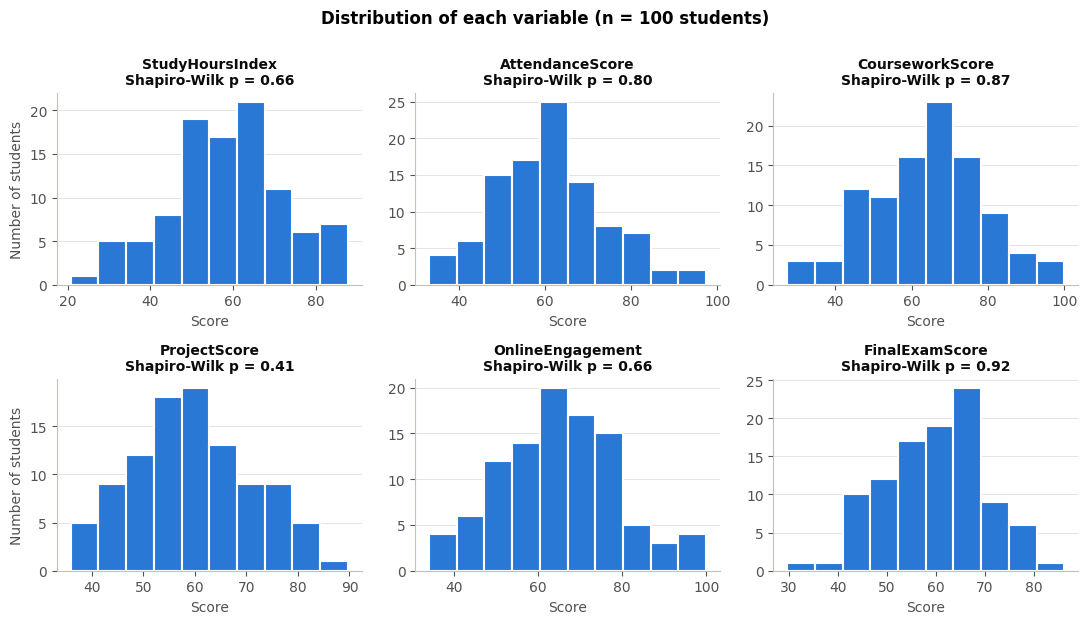

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for ax, col in zip(axes.flat, df1.columns):
    ax.hist(df1[col], bins=10, color=BLUE, edgecolor='white', linewidth=1.5)
    p = stats.shapiro(df1[col]).pvalue
    ax.set_title(f'{col}\nShapiro-Wilk p = {p:.2f}', fontsize=10)
    ax.set_xlabel('Score')
    ax.grid(axis='y'); ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel('Number of students')
fig.suptitle('Distribution of each variable (n = 100 students)', fontweight='bold', y=1.0)
plt.tight_layout(); save('q1_fig1_distributions'); plt.show()

**Interpretation.** All six variables are roughly bell-shaped and every Shapiro-Wilk p-value is above 0.05 (the smallest is 0.41 for ProjectScore), so there is no evidence against normality. Skewness is small (between -0.18 and 0.25). The box-plot rule flags only five mild outliers in the whole dataset (no more than two per variable). They are plausible scores inside the 0 to 100 range, so they were kept.

### 1.2 Correlation analysis

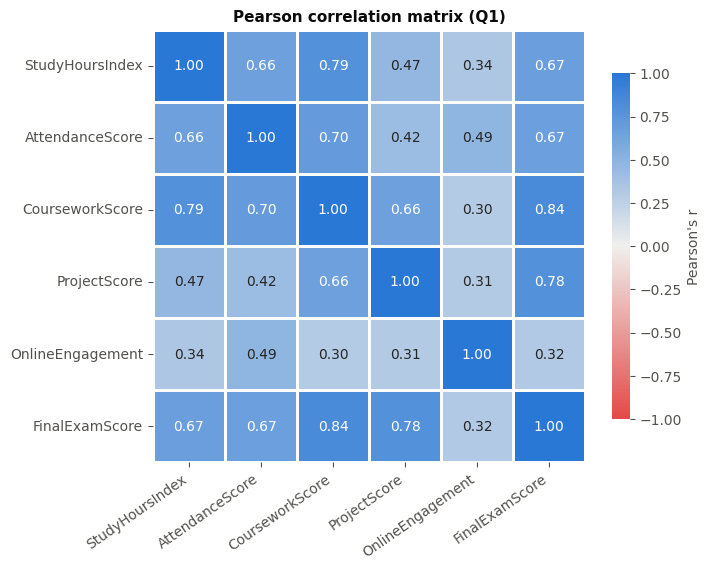

In [18]:
corr1 = df1.corr(method='pearson')
fig, ax = plt.subplots(figsize=(7.2, 5.8))
sns.heatmap(corr1, annot=True, fmt='.2f', cmap=DIVERGING, vmin=-1, vmax=1, square=True,
            linewidths=2, linecolor='white', cbar_kws={'label': "Pearson's r", 'shrink': 0.8}, ax=ax)
ax.set_title('Pearson correlation matrix (Q1)')
plt.xticks(rotation=35, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); save('q1_fig2_correlation'); plt.show()

In [19]:
# Correlation of each indicator with FinalExamScore: Pearson (linear) and Spearman (rank-based check)
rows = []
for c in df1.columns.drop('FinalExamScore'):
    r, p = stats.pearsonr(df1[c], df1['FinalExamScore'])
    rho, p_rho = stats.spearmanr(df1[c], df1['FinalExamScore'])
    rows.append([c, r, p, rho, p_rho])
q1_corr = (pd.DataFrame(rows, columns=['Indicator', 'Pearson r', 'p-value', 'Spearman rho', 'Spearman p'])
             .sort_values('Pearson r', ascending=False).reset_index(drop=True))
q1_corr.round(4)

,Indicator,Pearson r,p-value,Spearman rho,Spearman p
0,CourseworkScore,0.8365,0.0000,0.8404,0.0000
1,ProjectScore,0.7827,0.0000,0.7772,0.0000
2,StudyHoursIndex,0.6738,0.0000,0.6422,0.0000
3,AttendanceScore,0.6690,0.0000,0.6577,0.0000
4,OnlineEngagement,0.3152,0.0014,0.2515,0.0116


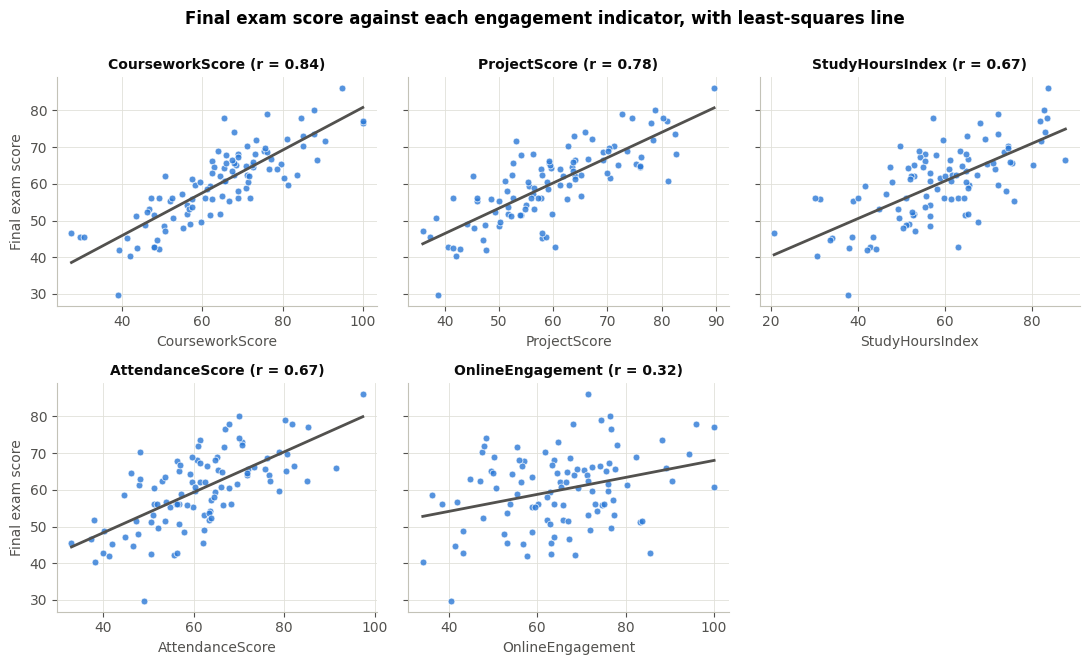

In [20]:
order = q1_corr['Indicator'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), sharey=True)
for ax, c in zip(axes.flat, order):
    ax.scatter(df1[c], df1['FinalExamScore'], s=24, color=BLUE, alpha=0.8, edgecolor='white', linewidth=0.6)
    slope, intercept = np.polyfit(df1[c], df1['FinalExamScore'], 1)
    xs = np.linspace(df1[c].min(), df1[c].max(), 50)
    ax.plot(xs, intercept + slope*xs, color=INK2, lw=2)
    r = stats.pearsonr(df1[c], df1['FinalExamScore'])[0]
    ax.set_title(f'{c} (r = {r:.2f})', fontsize=10)
    ax.set_xlabel(c)
    ax.grid(True); ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel('Final exam score')
axes.flat[-1].axis('off')
fig.suptitle('Final exam score against each engagement indicator, with least-squares line', fontweight='bold', y=1.0)
plt.tight_layout(); save('q1_fig3_scatter'); plt.show()

**Interpretation.** Every indicator is positively and significantly correlated with FinalExamScore (all p < 0.05). Using the Week 5 wording, CourseworkScore (r = 0.84) and ProjectScore (r = 0.78) are strong, StudyHoursIndex and AttendanceScore (both r = 0.67) are moderate to strong, and OnlineEngagement (r = 0.32) is weak. Spearman's rho gives the same ranking, so the result does not depend on the normality assumption. The scatter plots show straight-line patterns with no curvature, so a linear model is reasonable.

The indicators are also correlated with each other, especially StudyHoursIndex with CourseworkScore (r = 0.79) and AttendanceScore with CourseworkScore (r = 0.70). That overlap matters in the regression below.

### 1.3 Multiple regression with backward elimination

Start with all five indicators, then remove the predictor with the largest p-value (if above 0.05) and refit, until every remaining coefficient is significant at the 5% level (the Week 6 approach).

In [21]:
X_full = df1.drop(columns='FinalExamScore')
model_full = sm.OLS(df1['FinalExamScore'], sm.add_constant(X_full)).fit()
print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:         FinalExamScore   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.805
Method:                 Least Squares   F-statistic:                     82.51
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           7.77e-33
Time:                        22:35:52   Log-Likelihood:                -290.65
No. Observations:                 100   AIC:                             593.3
Df Residuals:                      94   BIC:                             608.9
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                9.8781      2.961  

In [22]:
predictors = list(X_full.columns)
while True:
    model = sm.OLS(df1['FinalExamScore'], sm.add_constant(df1[predictors])).fit()
    pvals = model.pvalues.drop('const')
    print(f"{len(predictors)} predictors | adj R2 = {model.rsquared_adj:.3f} | largest p = {pvals.max():.4f} ({pvals.idxmax()})")
    if pvals.max() < 0.05:
        break
    predictors.remove(pvals.idxmax())   # drop the least significant predictor and refit

final_model = model
print('\nFinal predictors:', predictors)
print(final_model.summary())

5 predictors | adj R2 = 0.805 | largest p = 0.4455 (StudyHoursIndex)
4 predictors | adj R2 = 0.805 | largest p = 0.3364 (OnlineEngagement)
3 predictors | adj R2 = 0.806 | largest p = 0.0023 (AttendanceScore)

Final predictors: ['AttendanceScore', 'CourseworkScore', 'ProjectScore']
                            OLS Regression Results                            
Dep. Variable:         FinalExamScore   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     137.7
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.19e-34
Time:                        22:35:52   Log-Likelihood:                -291.45
No. Observations:                 100   AIC:                             590.9
Df Residuals:                      96   BIC:                             601.3
Df Model:                           3                                         
Covaria

In [23]:
# Compare with one-predictor (simple) regressions, as in Week 6 Q3(e)
rows = []
for c in X_full.columns:
    m = sm.OLS(df1['FinalExamScore'], sm.add_constant(df1[c])).fit()
    rows.append([c, m.params[c], m.pvalues[c], m.rsquared])
pd.DataFrame(rows, columns=['Indicator', 'Slope', 'p-value', 'R2']).sort_values('R2', ascending=False).round(4)

,Indicator,Slope,p-value,R2
2,CourseworkScore,0.5820,0.0000,0.6998
3,ProjectScore,0.6888,0.0000,0.6127
0,StudyHoursIndex,0.5107,0.0000,0.4540
1,AttendanceScore,0.5514,0.0000,0.4476
4,OnlineEngagement,0.2316,0.0014,0.0993


**Interpretation.** With all five predictors, R² = 0.814, but StudyHoursIndex (p = 0.445) and OnlineEngagement (p = 0.303) are not significant. Backward elimination removed StudyHoursIndex first, then OnlineEngagement (p = 0.336), leaving:

FinalExamScore = 9.30 + 0.161 × AttendanceScore + 0.292 × CourseworkScore + 0.371 × ProjectScore

All three coefficients are significant (all p < 0.01). R² = 0.811 and adjusted R² = 0.806 (F = 137.7, p < 0.001), so the reduced model explains 81% of the variation in exam scores, the same as the full model but with two fewer predictors. Holding the others fixed, each extra project point goes with 0.37 more exam marks, each extra coursework point with 0.29 and each extra attendance point with 0.16.

Why did StudyHoursIndex drop out when its correlation with the exam is 0.67? On its own it explains 45% of the variation, but it is strongly correlated with CourseworkScore (r = 0.79). Once coursework is in the model, study hours adds almost nothing new.

### 1.4 Checking the regression assumptions

In [24]:
resid = final_model.resid
print('Shapiro-Wilk on residuals:', stats.shapiro(resid))
print('Durbin-Watson:', round(sm.stats.durbin_watson(resid), 3), '(values between 1 and 3 suggest independent residuals)')
print('Correlations between the retained predictors:')
print(df1[predictors].corr().round(2))

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9900861759106057), pvalue=np.float64(0.6715621068030758))
Durbin-Watson: 2.038 (values between 1 and 3 suggest independent residuals)
Correlations between the retained predictors:
                 AttendanceScore  CourseworkScore  ProjectScore
AttendanceScore             1.00             0.70          0.42
CourseworkScore             0.70             1.00          0.66
ProjectScore                0.42             0.66          1.00


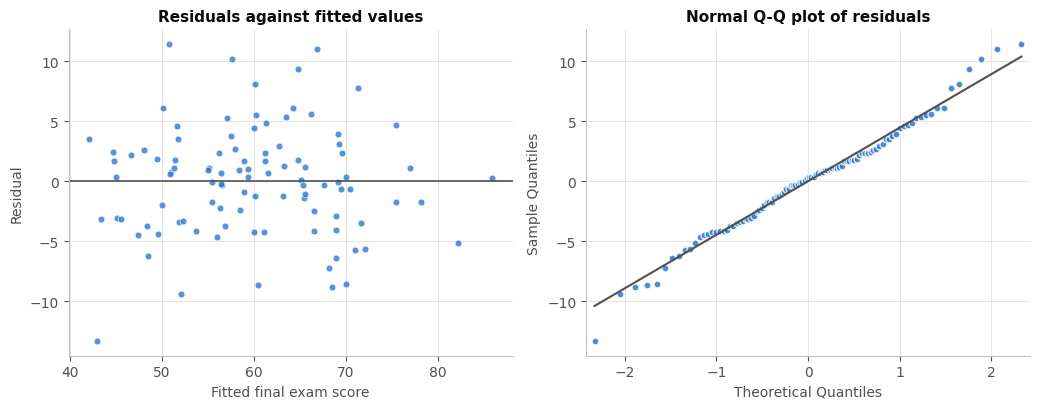

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].scatter(final_model.fittedvalues, resid, s=24, color=BLUE, alpha=0.8, edgecolor='white', linewidth=0.6)
axes[0].axhline(0, color=INK2, lw=1.2)
axes[0].set_xlabel('Fitted final exam score'); axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals against fitted values')
axes[0].grid(True); axes[0].set_axisbelow(True)
sm.qqplot(resid, line='s', ax=axes[1], marker='o', markersize=5,
          markerfacecolor=BLUE, markeredgecolor='white', alpha=0.85)
axes[1].get_lines()[1].set_color(INK2); axes[1].get_lines()[1].set_linewidth(1.5)
axes[1].set_title('Normal Q-Q plot of residuals')
axes[1].grid(True); axes[1].set_axisbelow(True)
plt.tight_layout(); save('q1_fig4_residuals'); plt.show()

**Interpretation.** The residuals pass every check. Shapiro-Wilk W = 0.990, p = 0.672, so they are consistent with a normal distribution. Durbin-Watson = 2.04, inside the 1 to 3 range, so they are independent. The residuals-against-fitted plot is a patternless band around zero with similar spread everywhere (constant variance), and the Q-Q plot follows the line. The retained predictors are correlated (up to r = 0.70), but all three coefficients stay clearly significant with narrow confidence intervals, so the overlap does not undermine the model. The model shows association within the observed range of scores, not cause and effect.

---
## Question 2: Can learner performance be described by fewer factors?

**Plan.** (1) Check the data and correlations: dimension reduction only makes sense if the skills are correlated. (2) PCA on standardised scores to decide how many dimensions to keep (Kaiser's eigenvalue > 1 rule, the scree plot and cumulative variance, as in Week 7). (3) Factor analysis to interpret the underlying constructs from the loadings. (4) Compare programmes in two ways: whether the same structure appears within each programme (the Week 7 LEADERSHIP approach), and whether factor scores differ between programmes (one-way ANOVA with Bonferroni post-hoc tests, Week 4).

In [26]:
df2 = pd.read_csv('Q2_dimensionality.csv')
skill_cols = ['MathSkill', 'StatisticsSkill', 'ProgrammingSkill', 'DataWrangling',
              'Visualisation', 'Communication', 'DomainKnowledge']
skills = df2[skill_cols]
print(df2.shape)
print('Missing values:', df2.isna().sum().sum())
print(df2['Programme'].value_counts())
skills.describe().round(2)

(100, 8)
Missing values: 0
Programme
Engineering    41
Business       33
Health         26
Name: count, dtype: int64


,MathSkill,StatisticsSkill,ProgrammingSkill,DataWrangling,Visualisation,Communication,DomainKnowledge
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,60.79,63.40,59.78,62.36,60.11,87.02,66.69
std,13.03,15.73,14.26,14.15,15.40,13.04,10.58
min,33.40,24.00,32.20,29.70,21.00,32.50,40.30
25%,50.70,53.10,50.70,52.95,50.20,80.62,58.98
50%,61.10,63.60,59.05,62.20,60.50,89.10,66.75
75%,68.60,74.15,68.00,72.40,70.80,99.70,73.38
max,100.00,100.00,100.00,99.70,97.90,100.00,96.00


In [27]:
q2_checks = pd.DataFrame({
    'Shapiro-Wilk p': [stats.shapiro(skills[c]).pvalue for c in skills],
    'Skewness': skills.skew().values,
    'Learners scoring 100': [(skills[c] == 100).sum() for c in skills]}, index=skill_cols)
q2_checks.round(3)

,Shapiro-Wilk p,Skewness,Learners scoring 100
MathSkill,0.254,0.306,1
StatisticsSkill,0.944,0.034,1
ProgrammingSkill,0.544,0.214,1
DataWrangling,0.964,-0.039,0
Visualisation,0.989,0.069,0
Communication,0.000,-1.213,25
DomainKnowledge,0.933,0.163,0


In [28]:
df2.groupby('Programme')[skill_cols].mean().round(1)

,MathSkill,StatisticsSkill,ProgrammingSkill,DataWrangling,Visualisation,Communication,DomainKnowledge
Programme,,,,,,,
Business,58.8,61.6,59.1,63.0,59.6,87.4,66.8
Engineering,59.0,60.3,56.2,59.2,58.1,88.5,62.1
Health,66.1,70.6,66.2,66.5,63.8,84.1,73.8


**Interpretation.** There are 100 learners (Engineering 41, Business 33, Health 26) and no missing values. Six skills look normally distributed (Shapiro-Wilk p > 0.05). Communication does not: it is negatively skewed (-1.21) and 25 learners scored the maximum of 100, a ceiling effect. Health learners have the highest average on six of the seven skills and the lowest on Communication.

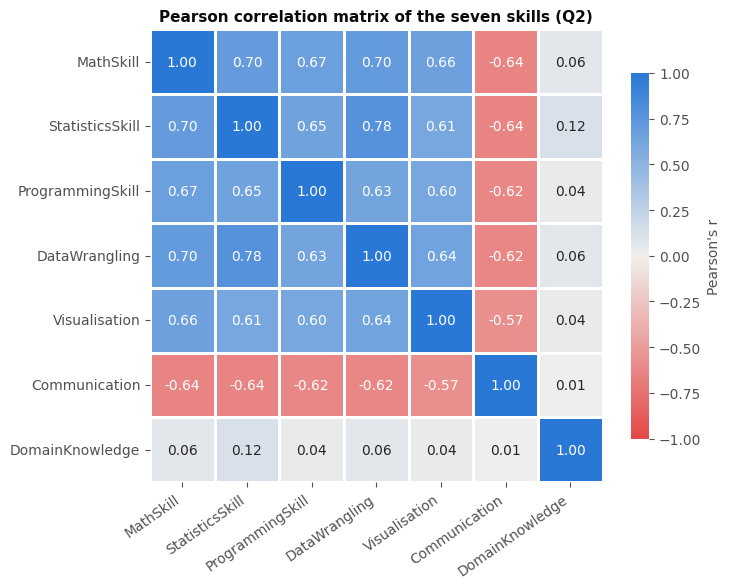

Largest absolute difference between Pearson and Spearman correlations: 0.067


In [29]:
corr2 = skills.corr(method='pearson')
fig, ax = plt.subplots(figsize=(7.4, 6))
sns.heatmap(corr2, annot=True, fmt='.2f', cmap=DIVERGING, vmin=-1, vmax=1, square=True,
            linewidths=2, linecolor='white', cbar_kws={'label': "Pearson's r", 'shrink': 0.8}, ax=ax)
ax.set_title('Pearson correlation matrix of the seven skills (Q2)')
plt.xticks(rotation=35, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); save('q2_fig5_correlation'); plt.show()

# Spearman check, because Communication is capped at 100 for many learners
print('Largest absolute difference between Pearson and Spearman correlations:',
      round((corr2 - skills.corr(method='spearman')).abs().values.max(), 3))

**Interpretation.** The correlation matrix shows a clear structure:

1. MathSkill, StatisticsSkill, ProgrammingSkill, DataWrangling and Visualisation are all moderately to strongly correlated with each other (r = 0.60 to 0.78).
2. Communication is negatively correlated with all five (r = -0.57 to -0.64): learners who score highly on technical skills tend to score lower on communication.
3. DomainKnowledge is essentially unrelated to everything else (|r| ≤ 0.12).

Spearman correlations differ from Pearson by at most 0.07, so the Communication ceiling does not distort this. Because most of the skills are correlated, dimension reduction is worth doing.

### 2.1 PCA: how many dimensions?

In [30]:
# Eigenvalues of the correlation matrix (same as PCA on standardised data)
eigenvalues = np.sort(np.linalg.eigvalsh(corr2))[::-1]
eigen_table = pd.DataFrame({
    'Eigenvalue': eigenvalues,
    'Proportion': eigenvalues / eigenvalues.sum(),
    'Cumulative': eigenvalues.cumsum() / eigenvalues.sum()},
    index=[f'PC{i}' for i in range(1, 8)])
eigen_table.round(3)

,Eigenvalue,Proportion,Cumulative
PC1,4.255,0.608,0.608
PC2,1.009,0.144,0.752
PC3,0.434,0.062,0.814
PC4,0.419,0.060,0.874
PC5,0.373,0.053,0.927
PC6,0.297,0.042,0.970
PC7,0.213,0.030,1.000


In [31]:
scaler = StandardScaler()
X2 = scaler.fit_transform(skills)
pca = PCA().fit(X2)
pc_loadings = pd.DataFrame(pca.components_.T, index=skill_cols, columns=[f'PC{i}' for i in range(1, 8)])
# eigenvector signs are arbitrary: make PC1 positive on MathSkill and PC2 positive on DomainKnowledge
if pc_loadings.loc['MathSkill', 'PC1'] < 0: pc_loadings['PC1'] *= -1
if pc_loadings.loc['DomainKnowledge', 'PC2'] < 0: pc_loadings['PC2'] *= -1
pc_loadings[['PC1', 'PC2', 'PC3']].round(3)

,PC1,PC2,PC3
MathSkill,0.421,-0.002,0.091
StatisticsSkill,0.422,0.081,-0.329
ProgrammingSkill,0.399,-0.045,0.056
DataWrangling,0.421,0.015,-0.183
Visualisation,0.390,-0.039,0.818
Communication,-0.392,0.117,0.421
DomainKnowledge,0.040,0.988,0.015


In [32]:
# The same eigenvalues within each programme (Week 7 LEADERSHIP approach)
PROG_COLOURS = {'Business': BLUE, 'Engineering': ORANGE, 'Health': AQUA}
prog_eigs = {}
for prog, d in df2.groupby('Programme'):
    ev = np.sort(np.linalg.eigvalsh(d[skill_cols].corr()))[::-1]
    prog_eigs[prog] = ev
    print(f"{prog:12s} n = {len(d):2d} | eigenvalues: {np.round(ev, 2)} | cumulative: {np.round(ev.cumsum()/ev.sum(), 2)}")

Business     n = 33 | eigenvalues: [3.91 0.99 0.64 0.56 0.38 0.33 0.2 ] | cumulative: [0.56 0.7  0.79 0.87 0.92 0.97 1.  ]
Engineering  n = 41 | eigenvalues: [3.9  1.02 0.65 0.53 0.44 0.26 0.19] | cumulative: [0.56 0.7  0.8  0.87 0.94 0.97 1.  ]
Health       n = 26 | eigenvalues: [4.87 1.05 0.39 0.27 0.2  0.11 0.1 ] | cumulative: [0.7  0.85 0.9  0.94 0.97 0.99 1.  ]


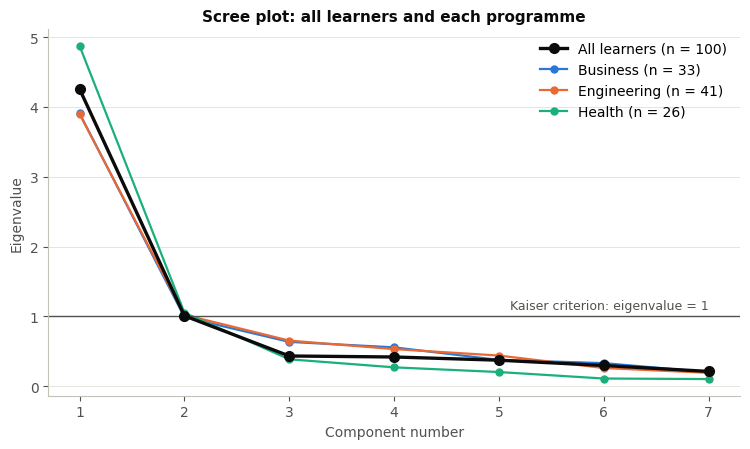

In [33]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
x = range(1, 8)
ax.plot(x, eigenvalues, marker='o', color=INK, lw=2.4, ms=7, label='All learners (n = 100)', zorder=3)
for prog, ev in prog_eigs.items():
    n = (df2['Programme'] == prog).sum()
    ax.plot(x, ev, marker='o', color=PROG_COLOURS[prog], lw=1.6, ms=5, label=f'{prog} (n = {n})')
ax.axhline(1, color=INK2, lw=1)
ax.text(7, 1.07, 'Kaiser criterion: eigenvalue = 1', ha='right', va='bottom', fontsize=9, color=INK2)
ax.set_xlabel('Component number'); ax.set_ylabel('Eigenvalue')
ax.set_title('Scree plot: all learners and each programme')
ax.set_xticks(list(x)); ax.grid(axis='y'); ax.set_axisbelow(True)
ax.legend()
plt.tight_layout(); save('q2_fig6_scree'); plt.show()

**Interpretation.** Two components have eigenvalues above 1 (4.25 and 1.01) and the scree plot bends sharply at component 2 and flattens after it. Together they explain 75.2% of the variance. Reaching the 80% guideline would need a third component (81.4%) whose eigenvalue is only 0.43, so two components are kept.

PC1 (60.8%) weights the five technical skills almost equally (0.39 to 0.42) and Communication negatively (-0.39). PC2 (14.4%) is almost entirely DomainKnowledge (weight 0.99). So the second dimension is one variable on its own rather than a group of related skills.

The same pattern appears within each programme: one dominant component (eigenvalue 3.91 Business, 3.90 Engineering, 4.87 Health) and a second of about 1. The first component is strongest in Health, where it explains 70% of the variance on its own (56% in Business and Engineering).

### 2.2 Factor analysis: what are the constructs?

In [34]:
def run_fa(data, n_factors, rotation):
    X = StandardScaler().fit_transform(data)
    fa = FactorAnalyzer(n_factors=n_factors, rotation=rotation)
    fa.fit(X)
    loadings = pd.DataFrame(fa.loadings_, index=data.columns,
                            columns=[f'Factor {i}' for i in range(1, n_factors + 1)])
    loadings['Communality'] = fa.get_communalities()
    return fa, loadings

# Two factors, as suggested by Kaiser's rule (varimax and promax rotations)
for rot in ['varimax', 'promax']:
    fa2, load2 = run_fa(skills, 2, rot)
    print(f'--- 2 factors, {rot} rotation ---')
    print(load2.round(2))
    print('Proportion of variance per factor:', np.round(fa2.get_factor_variance()[1], 3), '\n')

--- 2 factors, varimax rotation ---
                  Factor 1  Factor 2  Communality
MathSkill             0.83      0.16         0.72
StatisticsSkill       0.72      0.67         0.96
ProgrammingSkill      0.78      0.12         0.62
DataWrangling         0.77      0.33         0.71
Visualisation         0.76      0.10         0.59
Communication        -0.76     -0.12         0.59
DomainKnowledge       0.01      0.17         0.03
Proportion of variance per factor: [0.51  0.093] 

--- 2 factors, promax rotation ---
                  Factor 1  Factor 2  Communality
MathSkill             0.87     -0.04         0.75
StatisticsSkill       0.61      0.54         0.66
ProgrammingSkill      0.82     -0.07         0.68
DataWrangling         0.76      0.16         0.60
Visualisation         0.80     -0.09         0.65
Communication        -0.79      0.06         0.63
DomainKnowledge      -0.03      0.18         0.03
Proportion of variance per factor: [0.52  0.053] 



**Interpretation.** With two factors, the second factor is weak and has no clear meaning. It explains only 9.3% of the variance (varimax) or 5.3% (promax), its only notable loading is StatisticsSkill (which also loads on Factor 1, a cross-loading), and DomainKnowledge barely loads on it (0.17 to 0.18). This happens because factor analysis models only the variance that variables share, and DomainKnowledge shares almost none with the other skills (communality 0.03). A one-factor model describes the shared structure better.

In [35]:
# One-factor model
fa1, load1 = run_fa(skills, 1, None)
print(load1.round(2))
print('Proportion of variance explained by Factor 1:', round(fa1.get_factor_variance()[1][0], 3))

                  Factor 1  Communality
MathSkill             0.84         0.71
StatisticsSkill       0.85         0.72
ProgrammingSkill      0.78         0.61
DataWrangling         0.85         0.72
Visualisation         0.75         0.57
Communication        -0.76         0.58
DomainKnowledge       0.07         0.00
Proportion of variance explained by Factor 1: 0.559


In [36]:
# One-factor loadings within each programme: is the structure the same?
prog_load = pd.DataFrame({prog: run_fa(d[skill_cols], 1, None)[1]['Factor 1']
                          for prog, d in df2.groupby('Programme')})
prog_load = prog_load.apply(lambda col: col if col['MathSkill'] > 0 else -col)   # align signs
prog_load.insert(0, 'All learners', load1['Factor 1'])
prog_load.round(2)

,All learners,Business,Engineering,Health
MathSkill,0.84,0.89,0.75,0.89
StatisticsSkill,0.85,0.70,0.81,0.96
ProgrammingSkill,0.78,0.68,0.81,0.85
DataWrangling,0.85,0.83,0.82,0.86
Visualisation,0.75,0.70,0.65,0.88
Communication,-0.76,-0.71,-0.70,-0.81
DomainKnowledge,0.07,-0.26,-0.15,0.16


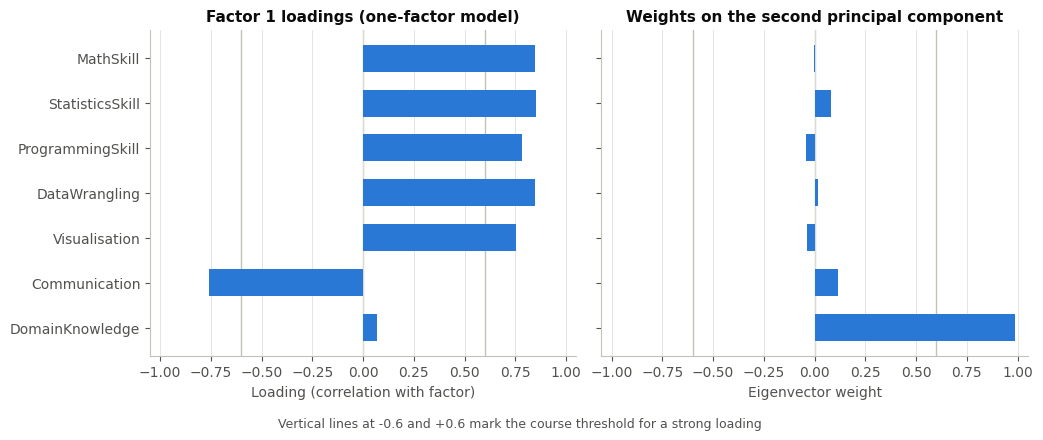

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
ylab = skill_cols[::-1]
axes[0].barh(ylab, load1['Factor 1'][ylab], color=BLUE, height=0.6)
axes[0].set_title('Factor 1 loadings (one-factor model)')
axes[0].set_xlabel('Loading (correlation with factor)')
axes[1].barh(ylab, pc_loadings['PC2'][ylab], color=BLUE, height=0.6)
axes[1].set_title('Weights on the second principal component')
axes[1].set_xlabel('Eigenvector weight')
for ax in axes:
    ax.axvline(0, color='#c3c2b7', lw=1, zorder=0)
    for t in (-0.6, 0.6):
        ax.axvline(t, color='#c3c2b7', lw=1, zorder=0)
    ax.set_xlim(-1.05, 1.05); ax.grid(axis='x'); ax.set_axisbelow(True)
fig.text(0.5, -0.03, 'Vertical lines at -0.6 and +0.6 mark the course threshold for a strong loading',
         ha='center', fontsize=9, color=INK2)
plt.tight_layout(); save('q2_fig7_loadings'); plt.show()

**Interpretation.** The one-factor model gives strong loadings (above 0.6) for MathSkill (0.84), StatisticsSkill (0.85), ProgrammingSkill (0.78), DataWrangling (0.85) and Visualisation (0.75), and a strong negative loading for Communication (-0.76). DomainKnowledge does not load (0.07). The factor explains 55.9% of the total variance and can be named **technical skill**. The suggested separate "numerical" and "computing" constructs are not supported, because maths and statistics load no differently from programming and data wrangling. Communication sits at the opposite end of the same factor.

Within each programme the same factor appears with the same signs, and the loadings are strongest for Health (0.85 to 0.96 for the technical skills). DomainKnowledge never loads strongly in any programme (-0.26 to 0.16), confirming it is a separate dimension.

### 2.3 Comparing programmes on the reduced dimensions

In [38]:
# Factor score for each learner on the technical factor (sign set so that higher = stronger technical skills)
scores = fa1.transform(StandardScaler().fit_transform(skills))[:, 0]
if np.corrcoef(scores, skills['MathSkill'])[0, 1] < 0:
    scores = -scores
df2['TechnicalFactor'] = scores

def compare_groups(data, value, group='Programme'):
    names = sorted(data[group].unique())
    g = [data.loc[data[group] == n, value] for n in names]
    print(f'===== {value} =====')
    print(data.groupby(group)[value].agg(['count', 'mean', 'std']).round(3))
    print('Shapiro-Wilk p per group:', [round(stats.shapiro(x).pvalue, 3) for x in g])
    print('Levene (equal variances) p =', round(stats.levene(*g).pvalue, 4))
    F = stats.f_oneway(*g)
    print(f'One-way ANOVA: F = {F.statistic:.2f}, p = {F.pvalue:.4f}')
    H = stats.kruskal(*g)
    print(f'Kruskal-Wallis: H = {H.statistic:.2f}, p = {H.pvalue:.4f}')
    print('Bonferroni-adjusted pairwise t-tests:')
    pairs = list(itertools.combinations(range(len(names)), 2))
    for a, b in pairs:
        p = stats.ttest_ind(g[a], g[b]).pvalue
        print(f'   {names[a]} vs {names[b]}: p = {min(1, p*len(pairs)):.4f}')
    print()

compare_groups(df2, 'TechnicalFactor')
compare_groups(df2, 'DomainKnowledge')

===== TechnicalFactor =====
             count   mean    std
Programme                       
Business        33 -0.069  0.814
Engineering     41 -0.202  0.854
Health          26  0.406  1.196
Shapiro-Wilk p per group: [np.float64(0.354), np.float64(0.23), np.float64(0.887)]
Levene (equal variances) p = 0.0764
One-way ANOVA: F = 3.44, p = 0.0359
Kruskal-Wallis: H = 4.82, p = 0.0899
Bonferroni-adjusted pairwise t-tests:
   Business vs Engineering: p = 1.0000
   Business vs Health: p = 0.2260
   Engineering vs Health: p = 0.0541

===== DomainKnowledge =====
             count    mean     std
Programme                         
Business        33  66.842   8.093
Engineering     41  62.083   9.881
Health          26  73.781  10.788
Shapiro-Wilk p per group: [np.float64(0.663), np.float64(0.82), np.float64(0.979)]
Levene (equal variances) p = 0.2034
One-way ANOVA: F = 11.86, p = 0.0000
Kruskal-Wallis: H = 17.35, p = 0.0002
Bonferroni-adjusted pairwise t-tests:
   Business vs Engineering: p =

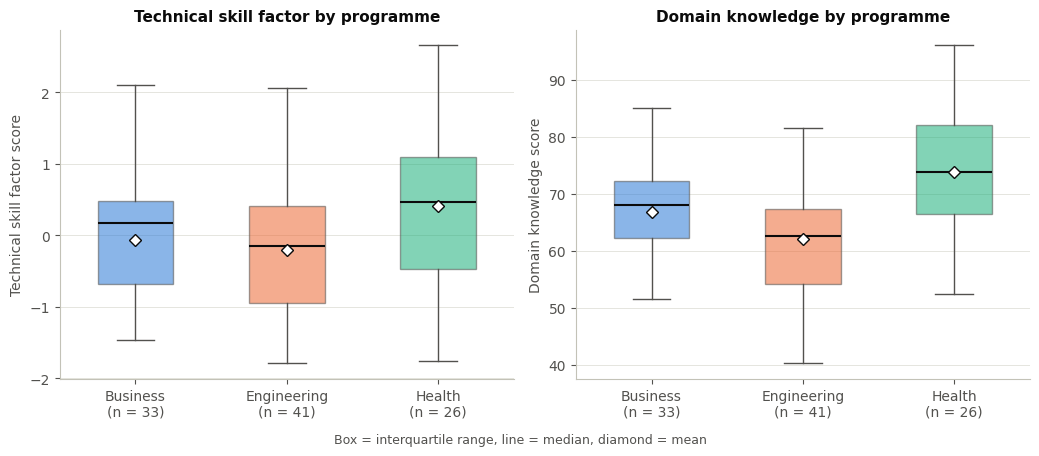

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
progs = ['Business', 'Engineering', 'Health']
for ax, var, lab in zip(axes, ['TechnicalFactor', 'DomainKnowledge'],
                        ['Technical skill factor score', 'Domain knowledge score']):
    data = [df2.loc[df2['Programme'] == p, var] for p in progs]
    bp = ax.boxplot(data, patch_artist=True, widths=0.5, showmeans=True,
                    medianprops=dict(color=INK, lw=1.5),
                    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor=INK, markersize=6),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                    flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor=INK2, markersize=4))
    for patch, p in zip(bp['boxes'], progs):
        patch.set_facecolor(PROG_COLOURS[p]); patch.set_alpha(0.55); patch.set_edgecolor(INK2)
    ax.set_xticks([1, 2, 3], [f'{p}\n(n = {len(d)})' for p, d in zip(progs, data)])
    ax.set_ylabel(lab); ax.grid(axis='y'); ax.set_axisbelow(True)
axes[0].set_title('Technical skill factor by programme')
axes[1].set_title('Domain knowledge by programme')
fig.text(0.5, -0.02, 'Box = interquartile range, line = median, diamond = mean', ha='center', fontsize=9, color=INK2)
plt.tight_layout(); save('q2_fig8_programmes'); plt.show()

**Interpretation.**

*Technical factor.* Each group looks normal (Shapiro-Wilk p ≥ 0.23) and the variances are similar enough (Levene p = 0.076). The one-way ANOVA is only just significant (F = 3.44, p = 0.036), with Health highest (mean 0.41) and Engineering lowest (-0.20). The evidence is weak, though: no pair differs after Bonferroni correction (Engineering vs Health p = 0.054) and the Kruskal-Wallis test is not significant (p = 0.090). Any programme difference in technical skill is small and uncertain.

*Domain knowledge.* The differences are clear (ANOVA F = 11.86, p < 0.001; Kruskal-Wallis p < 0.001; assumptions met). Health learners (mean 73.8) score higher than Engineering (62.1, Bonferroni p < 0.001) and Business (66.8, p = 0.020). Business and Engineering do not differ significantly (p = 0.087).

---
## Question 3: Are there distinct customer clusters?

**Plan.** (1) Check the data and correlations. (2) Standardise the five features so no feature dominates the distance calculation (Week 8). (3) Choose the number of clusters with four methods: elbow (WCSS), silhouette score, Davies-Bouldin index and gap statistic. (4) Run k-means, profile the clusters and visualise them in two dimensions with MDS. (5) Confirm with hierarchical clustering (Ward's method and a dendrogram). (6) Test whether the clusters differ on each feature (one-way ANOVA and Kruskal-Wallis with Bonferroni post-hoc tests).

In [40]:
df3 = pd.read_csv('Q3_clustering.csv')
features = ['AnnualSpend', 'PurchaseFreq', 'Discount', 'Promotion', 'Loyalty']
print(df3.shape)
print('Missing values:', df3.isna().sum().sum(), '| Duplicate rows:', df3.duplicated().sum())
df3.describe().round(2)

(110, 5)
Missing values: 0 | Duplicate rows: 0


,AnnualSpend,PurchaseFreq,Discount,Promotion,Loyalty
count,110.00,110.00,110.00,110.00,110.00
mean,55.91,56.86,51.97,48.65,56.90
std,20.74,18.98,23.21,24.64,26.83
min,15.40,20.60,12.20,0.00,7.60
25%,37.30,39.17,29.08,24.78,31.05
50%,57.10,56.45,52.70,53.60,57.80
75%,73.55,72.22,71.20,71.08,80.65
max,96.50,95.70,95.50,92.40,100.00


In [41]:
print(df3[features].corr().round(2))
scaler3 = StandardScaler()
X3 = scaler3.fit_transform(df3[features])
pca3 = PCA().fit(X3)
print('\nShare of variance on the first principal component:', round(pca3.explained_variance_ratio_[0], 3))

              AnnualSpend  PurchaseFreq  Discount  Promotion  Loyalty
AnnualSpend          1.00          0.86     -0.89      -0.88     0.88
PurchaseFreq         0.86          1.00     -0.85      -0.84     0.84
Discount            -0.89         -0.85      1.00       0.87    -0.89
Promotion           -0.88         -0.84      0.87       1.00    -0.88
Loyalty              0.88          0.84     -0.89      -0.88     1.00

Share of variance on the first principal component: 0.895


**Interpretation.** 110 customers, five features, no missing values or duplicates. The features are very strongly correlated (|r| = 0.84 to 0.89): spend, purchase frequency and loyalty rise together, while discount and promotion sensitivity move the other way. The first principal component alone explains 89.5% of the variance, so customers differ mainly along one spectrum, from loyal high-value buyers to deal-driven buyers. The features were standardised before clustering, as recommended in Week 8.

### 3.1 Choosing the number of clusters

In [42]:
wcss, sil, dbi = [], {}, {}
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X3)
    wcss.append(km.inertia_)
    if k > 1:
        sil[k] = silhouette_score(X3, km.labels_)
        dbi[k] = davies_bouldin_score(X3, km.labels_)

def gap_statistic(X, max_k=10, n_refs=20):
    # course function (Week 8): compare log(WCSS) with that of uniform random reference data
    gaps = []
    for k in range(1, max_k + 1):
        wk = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X).inertia_
        ref_dispersions = []
        for _ in range(n_refs):
            random_data = np.random.uniform(X.min(axis=0), X.max(axis=0), size=X.shape)
            ref_dispersions.append(KMeans(n_clusters=k, random_state=42, n_init=20).fit(random_data).inertia_)
        gaps.append(np.mean(np.log(ref_dispersions)) - np.log(wk))
    return gaps

np.random.seed(42)   # makes the random reference data reproducible
gaps = gap_statistic(X3)

k_table = pd.DataFrame({'WCSS': wcss, 'Silhouette': [np.nan] + list(sil.values()),
                        'Davies-Bouldin': [np.nan] + list(dbi.values()), 'Gap': gaps}, index=range(1, 11))
k_table.index.name = 'k'
k_table.round(3)

,WCSS,Silhouette,Davies-Bouldin,Gap
k,,,,
1,550.000,NaN,NaN,0.144
2,169.741,0.572,0.571,1.113
3,69.500,0.586,0.595,1.828
4,63.014,0.438,1.149,1.809
5,58.617,0.300,1.563,1.763
6,53.707,0.188,1.745,1.744
7,50.832,0.175,1.697,1.702
8,48.087,0.179,1.645,1.683
9,45.483,0.174,1.632,1.676


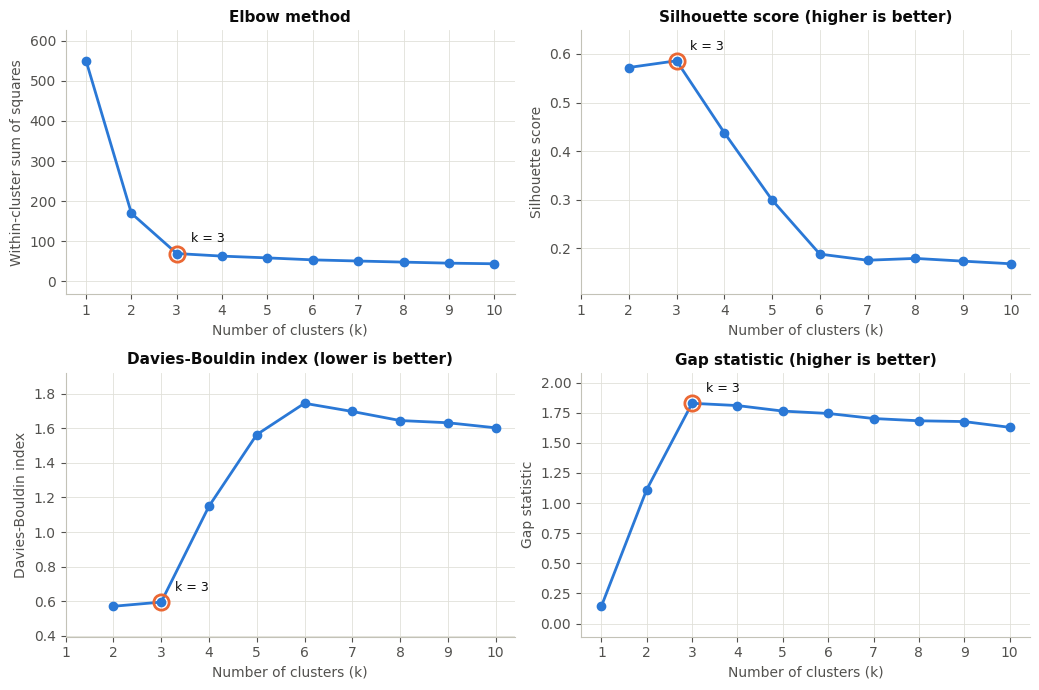

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7))
panels = [(axes[0, 0], range(1, 11), wcss, 'Elbow method', 'Within-cluster sum of squares'),
          (axes[0, 1], list(sil), list(sil.values()), 'Silhouette score (higher is better)', 'Silhouette score'),
          (axes[1, 0], list(dbi), list(dbi.values()), 'Davies-Bouldin index (lower is better)', 'Davies-Bouldin index'),
          (axes[1, 1], range(1, 11), gaps, 'Gap statistic (higher is better)', 'Gap statistic')]
for ax, ks, vals, title, ylab in panels:
    ks, vals = list(ks), list(vals)
    ax.plot(ks, vals, marker='o', color=BLUE, lw=2, ms=6)
    i3 = ks.index(3)
    ax.plot(3, vals[i3], marker='o', ms=11, markerfacecolor='none', markeredgecolor=ORANGE, markeredgewidth=2)
    ax.annotate('k = 3', (3, vals[i3]), textcoords='offset points', xytext=(10, 8), color=INK, fontsize=9)
    ax.set_title(title); ax.set_xlabel('Number of clusters (k)'); ax.set_ylabel(ylab)
    ax.set_xticks(range(1, 11)); ax.grid(True); ax.set_axisbelow(True)
    ax.margins(y=0.15)
plt.tight_layout(); save('q3_fig9_choosing_k'); plt.show()

**Interpretation.** The methods point to k = 3. The elbow is clearly at 3 (WCSS falls from 550 to 170 to 70, then levels off), the silhouette score peaks at 3 (0.586) and the gap statistic peaks at 3 (1.828). The Davies-Bouldin index is marginally lower at k = 2 (0.571) than at k = 3 (0.595), but both are low and it jumps to 1.149 at k = 4. Three of the four methods choose k = 3 and the fourth barely separates 2 and 3, so k = 3 is used.

### 3.2 k-means with k = 3

In [44]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=20).fit(X3)
# Number the clusters by average annual spend (highest first) so the labels are stable
rank = pd.Series(df3['AnnualSpend'].groupby(kmeans.labels_).mean()).rank(ascending=False).astype(int)
df3['Cluster'] = [rank[l] for l in kmeans.labels_]

centres = pd.DataFrame(scaler3.inverse_transform(kmeans.cluster_centers_), columns=features)
centres.index = [rank[i] for i in range(3)]
print('Cluster sizes:', df3['Cluster'].value_counts().sort_index().to_dict())
profile = df3.groupby('Cluster')[features].agg(['mean', 'std']).round(1)
profile

Cluster sizes: {1: 40, 2: 35, 3: 35}


AnnualSpend      PurchaseFreq      Discount      Promotion       \
               mean  std         mean  std     mean  std      mean  std   
Cluster                                                                   
1              78.5  7.3         76.4  9.0     26.5  7.1      20.2  9.4   
2              54.8  6.6         56.3  9.0     53.9  7.7      55.0  9.3   
3              31.2  7.0         35.1  6.7     79.2  9.0      74.9  7.5   

        Loyalty       
           mean  std  
Cluster               
1          86.3  8.7  
2          55.7  8.2  
3          24.5  7.2

In [45]:
# Stability: does k-means give the same clusters with different random starts?
for seed in range(5):
    lab = KMeans(n_clusters=3, random_state=seed, n_init=20).fit(X3).labels_
    print(f'random_state = {seed}: adjusted Rand index with the chosen solution = {adjusted_rand_score(df3["Cluster"], lab):.3f}')

random_state = 0: adjusted Rand index with the chosen solution = 1.000
random_state = 1: adjusted Rand index with the chosen solution = 1.000
random_state = 2: adjusted Rand index with the chosen solution = 1.000
random_state = 3: adjusted Rand index with the chosen solution = 1.000
random_state = 4: adjusted Rand index with the chosen solution = 1.000


**Interpretation.** k-means with k = 3 gives clusters of 40, 35 and 35 customers. The solution is completely stable: five different random starts give identical clusters (adjusted Rand index = 1, meaning perfect agreement).

- **Cluster 1, loyal high spenders (n = 40):** high spend (78.5) and purchase frequency (76.4), very high loyalty (86.3), and little interest in discounts (26.5) or promotions (20.2).
- **Cluster 2, mid-range customers (n = 35):** moderate on every feature (54.8 to 56.3).
- **Cluster 3, deal seekers (n = 35):** low spend (31.2), frequency (35.1) and loyalty (24.5), but very responsive to discounts (79.2) and promotions (74.9).

The MDS map below shows three separate groups laid out along one direction, with the mid-range customers between the other two.

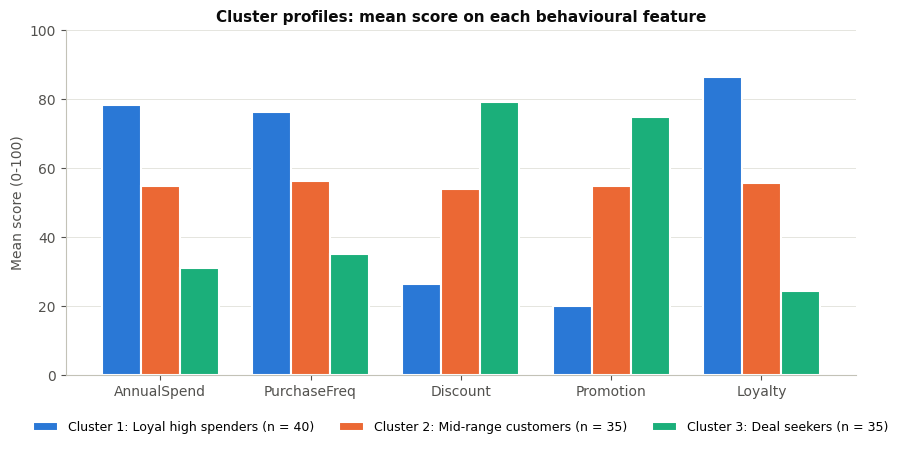

In [46]:
CLUSTER_NAMES = {1: 'Cluster 1: Loyal high spenders', 2: 'Cluster 2: Mid-range customers', 3: 'Cluster 3: Deal seekers'}
CLUSTER_COLOURS = {1: BLUE, 2: ORANGE, 3: AQUA}
CLUSTER_MARKERS = {1: 'o', 2: 's', 3: '^'}

means = df3.groupby('Cluster')[features].mean()
fig, ax = plt.subplots(figsize=(9.5, 4.6))
w = 0.26
for i, c in enumerate([1, 2, 3]):
    n = (df3['Cluster'] == c).sum()
    ax.bar(np.arange(5) + (i - 1)*w, means.loc[c], width=w, color=CLUSTER_COLOURS[c],
           edgecolor='white', linewidth=1.5, label=f'{CLUSTER_NAMES[c]} (n = {n})')
ax.set_xticks(range(5), features)
ax.set_ylabel('Mean score (0-100)'); ax.set_ylim(0, 100)
ax.set_title('Cluster profiles: mean score on each behavioural feature')
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9)
plt.tight_layout(); save('q3_fig10_profiles'); plt.show()

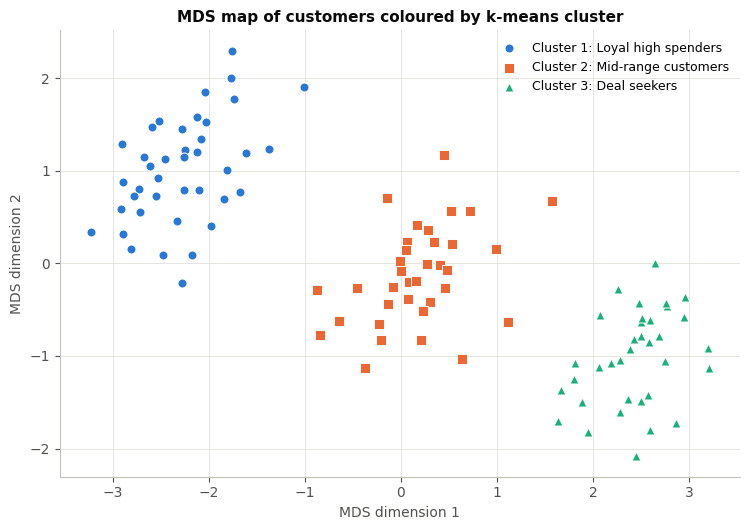

In [47]:
mds = MDS(n_components=2, random_state=42)
X_mds = mds.fit_transform(X3)
fig, ax = plt.subplots(figsize=(7.6, 5.4))
for c in [1, 2, 3]:
    m = df3['Cluster'] == c
    ax.scatter(X_mds[m, 0], X_mds[m, 1], s=42, color=CLUSTER_COLOURS[c], marker=CLUSTER_MARKERS[c],
               edgecolor='white', linewidth=0.7, label=CLUSTER_NAMES[c])
ax.set_xlabel('MDS dimension 1'); ax.set_ylabel('MDS dimension 2')
ax.set_title('MDS map of customers coloured by k-means cluster')
ax.grid(True); ax.set_axisbelow(True); ax.legend(fontsize=9)
plt.tight_layout(); save('q3_fig11_mds'); plt.show()

### 3.3 Hierarchical clustering check (Ward's method)

In [48]:
Z = linkage(X3, method='ward')
df3['Ward'] = fcluster(Z, t=3, criterion='maxclust')
print(pd.crosstab(df3['Cluster'], df3['Ward'], rownames=['k-means cluster'], colnames=['Ward cluster']))
print('Heights of the last three merges:', np.round(Z[-3:, 2], 2))

Ward cluster      1   2   3
k-means cluster            
1                40   0   0
2                 0   0  35
3                 0  35   0
Heights of the last three merges: [ 3.21 14.23 27.54]


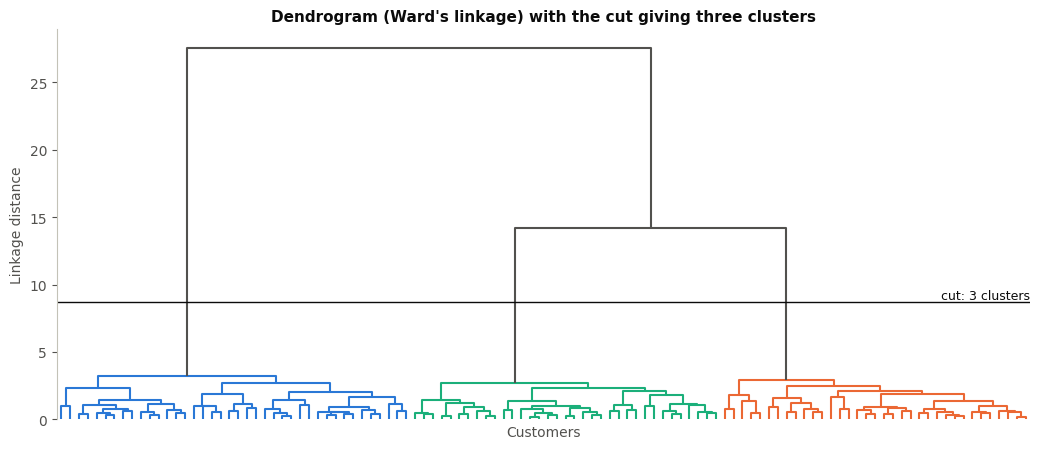

In [49]:
cut = (Z[-2, 2] + Z[-3, 2]) / 2          # a height between the 3-cluster and 2-cluster merges
# colour each Ward branch with the colour of the k-means cluster it matches
leaves = dendrogram(Z, no_plot=True)['leaves']
ward_to_kmeans = pd.crosstab(df3['Ward'], df3['Cluster']).idxmax(axis=1)
branch_order = list(dict.fromkeys(ward_to_kmeans[df3['Ward'].iloc[leaves]].tolist()))
set_link_color_palette([CLUSTER_COLOURS[c] for c in branch_order])

fig, ax = plt.subplots(figsize=(10.5, 4.6))
dendrogram(Z, color_threshold=cut, above_threshold_color=INK2, no_labels=True, ax=ax)
ax.axhline(cut, color=INK, lw=1)
ax.text(len(leaves)*10, cut, '  cut: 3 clusters', va='bottom', ha='right', fontsize=9, color=INK)
ax.set_title("Dendrogram (Ward's linkage) with the cut giving three clusters")
ax.set_xlabel('Customers'); ax.set_ylabel('Linkage distance')
ax.spines['bottom'].set_visible(False)
plt.tight_layout(); save('q3_fig12_dendrogram'); plt.show()
set_link_color_palette(None)

**Interpretation.** Ward's hierarchical clustering cut at three clusters gives exactly the same groups as k-means (every customer matched). The long vertical branches above the cut show the three groups are well separated. The mid-range and deal-seeker clusters join first (at a distance of about 14) before both join the loyal high spenders (about 27.5), so those two groups are more alike than either is to the loyal high spenders.

### 3.4 Do the clusters differ significantly on each feature?

In [50]:
rows = []
pairs = list(itertools.combinations([1, 2, 3], 2))
for f in features:
    g = [df3.loc[df3['Cluster'] == c, f] for c in [1, 2, 3]]
    F = stats.f_oneway(*g); H = stats.kruskal(*g)
    pair_p = [min(1, stats.ttest_ind(g[a-1], g[b-1]).pvalue * len(pairs)) for a, b in pairs]
    rows.append([f, min(stats.shapiro(x).pvalue for x in g), stats.levene(*g).pvalue,
                 F.statistic, F.pvalue, H.statistic, H.pvalue, max(pair_p)])
q3_tests = pd.DataFrame(rows, columns=['Feature', 'Smallest Shapiro p', 'Levene p', 'ANOVA F', 'ANOVA p',
                                       'Kruskal-Wallis H', 'Kruskal-Wallis p', 'Largest Bonferroni p'])
pd.set_option('display.float_format', lambda v: f'{v:.3g}')
q3_tests

,Feature,Smallest Shapiro p,Levene p,ANOVA F,ANOVA p,Kruskal-Wallis H,Kruskal-Wallis p,Largest Bonferroni p
0,AnnualSpend,0.0118,0.796,429,7.58e-52,96.6,1.05e-21,4.53e-22
1,PurchaseFreq,0.427,0.306,227,3.27e-39,88,7.64e-20,4.28e-14
2,Discount,0.0643,0.233,413,4.96e-51,94.6,2.92e-21,5.15e-19
3,Promotion,0.432,0.227,372,6.78e-49,93.1,6.03e-21,3.12e-14
4,Loyalty,0.147,0.437,543,9.29e-57,95.7,1.63e-21,1.87e-24


**Interpretation.** The clusters differ significantly on every feature: ANOVA F ranges from 227 (PurchaseFreq) to 543 (Loyalty), all p < 0.001, and every pairwise comparison stays significant after Bonferroni correction. Variances are equal (Levene p ≥ 0.23). AnnualSpend is slightly non-normal in one cluster (Shapiro-Wilk p = 0.012), so the Kruskal-Wallis test was also run, and it agrees (all p < 0.001).

A caution: these tests use the same variables that formed the clusters, so significant differences are expected by construction. They confirm that the clusters differ on every feature. The stronger evidence that the groups are real is the agreement between the k-selection methods, the stability across random starts and the identical Ward solution.